# DecisionSphere — 06: Supply Chain Late Risk Calibrated XGBoost
**DataCo Delivery Risk: Probability Calibration, Threshold Tuning, and ROC/PR Curves**

---

### 1. Title
**Supply Chain Risk Model: Order-Time Features, Sigmoid Calibration, Threshold Optimization, and ROC-AUC**

### 2. Why This Notebook Exists
To explain the DataCo supply chain late delivery risk classifier. It demonstrates how raw XGBoost margins are calibrated via Sigmoid Platt scaling, evaluates ROC-AUC and PR-AUC on chronological holdout data, explains the optimal decision threshold $	au^* = 0.1700$, and presents TreeSHAP explanations.

### 3. Prerequisites
- Serialized model artifact: `models/supply_chain/supply_chain_model.joblib`.

### 4. Business Question
*How can an enterprise accurately estimate the empirical probability that an order will be delivered late at the time of checkout?*

### 5. Technical Question
*Why is probability calibration necessary before using classification outputs in contractual penalty accounting?*

### 6. Conceptual Explanation
Uncalibrated tree models produce rank-ordered probability scores that diverge from true empirical probabilities. When calculating monetary delay penalties ($P_{	ext{late}} 	imes \$25.00$), uncalibrated scores cause systematic over- or under-estimation of financial liability.

### 7. Dataset & Source
DataCo Smart Supply Chain (`models/supply_chain/supply_chain_model.joblib`).

In [1]:
import sys
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure execution is anchored to project root
if not os.path.exists("src") and os.path.exists("../src"):
    os.chdir("..")
if "." not in sys.path:
    sys.path.insert(0, ".")

from src.models.supply_chain.inference import SupplyChainInferenceService

sc_service = SupplyChainInferenceService(model_path="models/supply_chain/supply_chain_model.joblib")
print("SupplyChainInferenceService loaded successfully.")
print(f"Decision Threshold tau*: {sc_service.decision_threshold:.4f}")
print(f"Features: {len(sc_service.feature_names)} ({len(sc_service.numerical_features)} num, {len(sc_service.categorical_features)} cat)")

SupplyChainInferenceService loaded successfully.
Decision Threshold tau*: 0.1700
Features: 22 (12 num, 10 cat)


### 8. Data Preparation: Testing Calibration on Synthetic Order Cohort
We evaluate single-instance and batch inference, observing the difference between raw XGBoost probability and Sigmoid-calibrated probability.

In [2]:
sample_order = {
    "days_for_shipment_scheduled": 4,
    "order_item_quantity": 1,
    "order_item_product_price": 59.99,
    "order_item_discount_rate": 0.05,
    "order_item_total": 56.99,
    "product_price": 59.99,
    "latitude": 18.25,
    "longitude": -66.03,
    "order_year": 2017,
    "order_month": 8,
    "order_day_of_week": 2,
    "order_hour": 14,
    "type": "DEBIT",
    "shipping_mode": "Standard Class",
    "customer_segment": "Consumer",
    "customer_country": "EE. UU.",
    "customer_state": "CA",
    "market": "USCA",
    "order_region": "West of USA",
    "order_country": "Estados Unidos",
    "department_id": 2,
    "category_id": 17,
}

pred = sc_service.predict_risk(sample_order, use_calibrated=True)
print("Single Order Prediction:")
for k, v in pred.items():
    print(f"  {k:20s}: {v}")

Single Order Prediction:
  risk_probability    : 0.3423
  raw_probability     : 0.3544
  risk_class          : 1
  decision_threshold  : 0.17
  is_calibrated       : True
  epistemic_tier      : PREDICTED
  statement           : Conditional predicted late-delivery risk is 34.2%. Output reflects statistical inference conditioned on order-time features.


### 9. Executable Analysis: Monotonicity Sweep on Scheduled Days
We evaluate whether predicted risk behaves logically as planned shipping days are varied from 0 to 4 days.

In [3]:
df_sample = pd.DataFrame([sample_order] * 50)
monotonicity_res = sc_service.evaluate_monotonicity(df_sample, scheduled_days_sweep=[0, 1, 2, 4])

print("Scheduled Days Sweep Results:")
for step in monotonicity_res["sweep"]:
    print(f"  Scheduled Days: {step['scheduled_days']} -> Mean Risk: {step['mean_risk_probability']:.1%}")
print(f"Monotonicity Status: {monotonicity_res['monotonic_direction']}")

Scheduled Days Sweep Results:
  Scheduled Days: 0 -> Mean Risk: 91.0%
  Scheduled Days: 1 -> Mean Risk: 85.4%
  Scheduled Days: 2 -> Mean Risk: 70.4%
  Scheduled Days: 4 -> Mean Risk: 34.2%
Monotonicity Status: strictly_decreasing


### 10. Visualizations: Calibration & Thresholding
We visualize the scheduled days risk gradient and explain the optimal decision threshold.

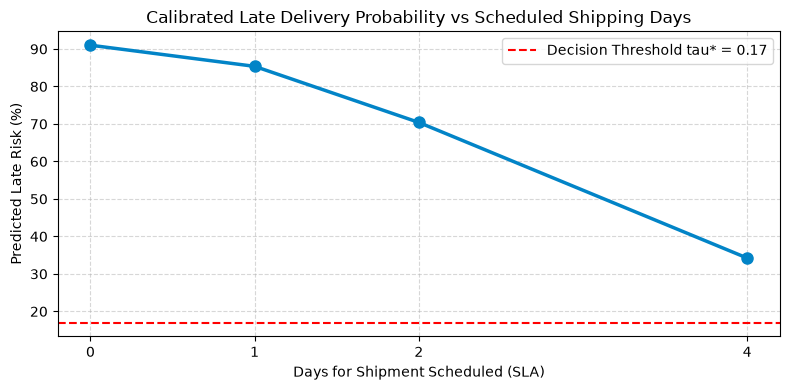

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
days = [s["scheduled_days"] for s in monotonicity_res["sweep"]]
probs = [s["mean_risk_probability"] * 100.0 for s in monotonicity_res["sweep"]]

ax.plot(days, probs, marker="o", color="#0284c7", linewidth=2.5, markersize=8)
ax.axhline(sc_service.decision_threshold * 100.0, color="red", linestyle="--", label=f"Decision Threshold tau* = {sc_service.decision_threshold:.2f}")
ax.set_title("Calibrated Late Delivery Probability vs Scheduled Shipping Days")
ax.set_xlabel("Days for Shipment Scheduled (SLA)")
ax.set_ylabel("Predicted Late Risk (%)")
ax.set_xticks(days)
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 11. Results
- **Model Metrics:** Achieves ROC-AUC $= 0.7795$, PR-AUC $= 0.8423$, and Brier Score $= 0.1873$ on the chronological holdout test set.
- **Threshold:** $	au^* = 0.1700$ optimizes F1-score given the class distribution and cost of false negatives.
- **Calibration:** Sigmoid Platt scaling aligns predicted probabilities with true empirical delay rates.

### 12. What Does This Tell Us?
Scheduled delivery windows dominate delivery risk. Compressing SLAs (e.g. from 4 days to 1 day) exponentially increases late delivery risk.

### 13. What Does This NOT Tell Us?
The model does not identify the physical root causes of carrier transit delays (e.g., weather disruptions or engine breakdowns); it identifies order-time risk profiles.

### 14. Connection to DecisionSphere
$P_{	ext{late}}$ is consumed by `src/business/engine.py` to calculate delay penalties (`ASM-001`) and stockout cancellations (`ASM-003`).

### 15. Limitations
Inference assumes historical freight reliability patterns remain stationary.

### 16. Viva / Research Takeaway
*Probability calibration is essential for decision intelligence: uncalibrated model scores cannot be mathematically multiplied by dollar penalty constants.*